# 07 — Supplementary Random Forest Model

This notebook evaluates Random Forest as a supplementary ensemble-learning
model beyond the project's five primary candidate classifiers.

The model uses the same finalized 15-feature pre-contact configuration and
70/15/15 stratified split as the primary models so that its performance can
be compared consistently.

In [48]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation import (
    evaluate_binary_classifier,
    plot_confusion_matrix,
    plot_roc_curve,
    cross_validate_classifier,
    cross_validation_results_to_dataframe,
    bootstrap_classification_metrics,
    bootstrap_results_to_dataframe,
)

from src.models import get_supplementary_models

## Data Loading

In [49]:
DATA_PATH = PROJECT_ROOT / "data" / "bank-full.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. "
        "Download bank-full.csv and place it in the data/ folder."
    )

df = pd.read_csv(
    DATA_PATH,
    sep=";",
)

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [50]:
X = df.drop(columns=["y"])

y = df["y"].map({
    "no": 0,
    "yes": 1,
})

## Finalized Pre-Contact Feature Set

Random Forest uses the same 15 pre-contact predictors as the primary
classification models.

`duration` is excluded because the duration of the current call is not
known at the pre-contact prediction point.

In [51]:
numeric_features = [
    "age",
    "balance",
    "day",
    "campaign",
    "pdays",
    "previous",
]

categorical_features = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "poutcome",
]

model_features = (
    numeric_features
    + categorical_features
)

X_model = X[model_features]

print(
    "Number of modeling features:",
    len(model_features),
)

print(model_features)

Number of modeling features: 15
['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


## Train / Validation / Test Split

The same stratified 70/15/15 split and `random_state=42` used by the
primary models are reproduced here.

In [52]:
X_train_model, X_temp_model, y_train_model, y_temp_model = train_test_split(
    X_model,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42,
)

X_test_model, X_val_model, y_test_model, y_val_model = train_test_split(
    X_temp_model,
    y_temp_model,
    test_size=0.50,
    stratify=y_temp_model,
    random_state=42,
)

print(
    "Training:",
    X_train_model.shape,
)

print(
    "Validation:",
    X_val_model.shape,
)

print(
    "Testing:",
    X_test_model.shape,
)

Training: (31647, 15)
Validation: (6782, 15)
Testing: (6782, 15)


## Random Forest Preprocessing

Random Forest does not require standardized numerical predictors because
tree splits are not based on Euclidean distance or coefficient scale.

Numeric predictors are therefore median-imputed without scaling.
Categorical predictors are imputed and one-hot encoded.

In [53]:
rf_numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
            ),
        ),
    ]
)

rf_categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent",
            ),
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True,
            ),
        ),
    ]
)

rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            rf_numeric_pipeline,
            numeric_features,
        ),
        (
            "categorical",
            rf_categorical_pipeline,
            categorical_features,
        ),
    ]
)

## Train Random Forest

The supplementary Random Forest uses 300 trees and balanced class weights.

`class_weight="balanced"` adjusts class weights according to the observed
class frequencies so that the minority subscriber class receives greater
weight during training.

In [54]:
supplementary_models = (
    get_supplementary_models()
)

rf_model = supplementary_models[
    "Random Forest"
]

rf_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            rf_preprocessor,
        ),
        (
            "classifier",
            rf_model,
        ),
    ]
)

rf_pipeline.fit(
    X_train_model,
    y_train_model,
)

rf_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['age','balance','day',...,'contact','month','poutcome']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, al

## Validation Evaluation

In [55]:
rf_val_predictions = (
    rf_pipeline.predict(
        X_val_model
    )
)

rf_val_probabilities = (
    rf_pipeline.predict_proba(
        X_val_model
    )[:, 1]
)

rf_val_results = (
    evaluate_binary_classifier(
        model_name="Random Forest",
        y_true=y_val_model,
        y_pred=rf_val_predictions,
        y_score=rf_val_probabilities,
    )
)

rf_val_results

{'model': 'Random Forest',
 'accuracy': 0.8821881450899439,
 'precision': 0.4954128440366973,
 'recall': 0.4085750315258512,
 'f1': 0.44782308223911543,
 'roc_auc': 0.7803862566870705}

## Final Test Evaluation

In [56]:
rf_predictions = (
    rf_pipeline.predict(
        X_test_model
    )
)

rf_probabilities = (
    rf_pipeline.predict_proba(
        X_test_model
    )[:, 1]
)

rf_results = (
    evaluate_binary_classifier(
        model_name="Random Forest",
        y_true=y_test_model,
        y_pred=rf_predictions,
        y_score=rf_probabilities,
    )
)

rf_results

{'model': 'Random Forest',
 'accuracy': 0.8833677381303451,
 'precision': 0.50231124807396,
 'recall': 0.4105793450881612,
 'f1': 0.4518364518364518,
 'roc_auc': 0.7948692304844786}

## Confusion Matrix

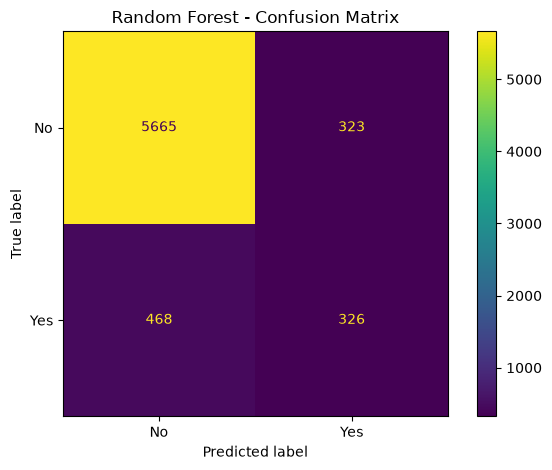

In [57]:
plot_confusion_matrix(
    y_true=y_test_model,
    y_pred=rf_predictions,
    model_name="Random Forest",
)

plt.show()

## ROC Curve

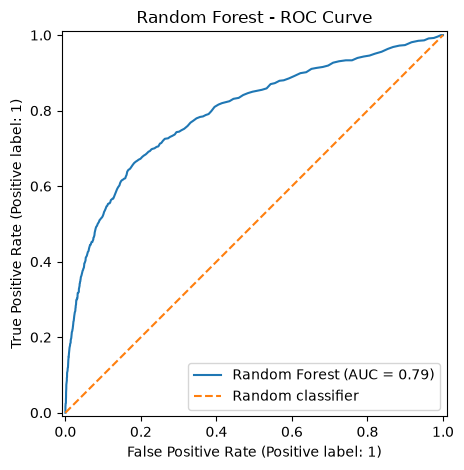

In [58]:
plot_roc_curve(
    y_true=y_test_model,
    y_score=rf_probabilities,
    model_name="Random Forest",
)

plt.show()

## Stratified 5-Fold Cross-Validation

The same shared stratified cross-validation framework used for the primary
models is applied to Random Forest.

In [59]:
rf_cv_results = (
    cross_validate_classifier(
        model_name="Random Forest",
        estimator=rf_pipeline,
        X=X_train_model,
        y=y_train_model,
        cv=5,
    )
)

rf_cv_results

{'model': 'Random Forest',
 'accuracy_mean': np.float64(0.8760387963128675),
 'accuracy_std': np.float64(0.0037021620947313137),
 'precision_mean': np.float64(0.46510740198821254),
 'precision_std': np.float64(0.018308831639390236),
 'recall_mean': np.float64(0.3959933617828354),
 'recall_std': np.float64(0.02081792193304232),
 'f1_mean': np.float64(0.4275693668089767),
 'f1_std': np.float64(0.017934919227246778),
 'roc_auc_mean': np.float64(0.7782311527497561),
 'roc_auc_std': np.float64(0.009909194440940069)}

In [60]:
rf_cv_results_df = (
    cross_validation_results_to_dataframe(
        [rf_cv_results]
    )
)

rf_cv_results_df.round(4)

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Random Forest,0.876,0.0037,0.4651,0.0183,0.396,0.0208,0.4276,0.0179,0.7782,0.0099


## Bootstrap Confidence Intervals

The fixed held-out Random Forest test predictions are resampled with
replacement 1,000 times to estimate 95% confidence intervals for the
project's classification metrics.

In [61]:
rf_bootstrap_results = (
    bootstrap_classification_metrics(
        model_name="Random Forest",
        y_true=y_test_model,
        y_pred=rf_predictions,
        y_score=rf_probabilities,
        n_bootstrap=1000,
        confidence_level=0.95,
        random_state=42,
    )
)

rf_bootstrap_results

{'model': 'Random Forest',
 'n_bootstrap': 1000,
 'confidence_level': 0.95,
 'accuracy': 0.8833677381303451,
 'accuracy_ci_lower': np.float64(0.875696697139487),
 'accuracy_ci_upper': np.float64(0.8911825420230021),
 'precision': 0.50231124807396,
 'precision_ci_lower': np.float64(0.4653571564739973),
 'precision_ci_upper': np.float64(0.5396619826862468),
 'recall': 0.4105793450881612,
 'recall_ci_lower': np.float64(0.3785140062066471),
 'recall_ci_upper': np.float64(0.44340909489102254),
 'f1': 0.4518364518364518,
 'f1_ci_lower': np.float64(0.4203350005270987),
 'f1_ci_upper': np.float64(0.48248898716841565),
 'roc_auc': 0.7948692304844786,
 'roc_auc_ci_lower': np.float64(0.775902648611318),
 'roc_auc_ci_upper': np.float64(0.8126239408354954)}

In [62]:
rf_bootstrap_df = (
    bootstrap_results_to_dataframe(
        [rf_bootstrap_results]
    )
)

rf_bootstrap_df

,model,n_bootstrap,confidence_level,accuracy,accuracy_ci_lower,accuracy_ci_upper,precision,precision_ci_lower,precision_ci_upper,recall,recall_ci_lower,recall_ci_upper,f1,f1_ci_lower,f1_ci_upper,roc_auc,roc_auc_ci_lower,roc_auc_ci_upper
0,Random Forest,1000,0.95,0.883368,0.875697,0.891183,0.502311,0.465357,0.539662,0.410579,0.378514,0.443409,0.451836,0.420335,0.482489,0.794869,0.775903,0.812624


In [63]:
rf_bootstrap_summary_df = pd.DataFrame({
    "Model": rf_bootstrap_df["model"],

    "Precision": rf_bootstrap_df.apply(
        lambda row: (
            f'{row["precision"]:.3f} '
            f'[{row["precision_ci_lower"]:.3f}, '
            f'{row["precision_ci_upper"]:.3f}]'
        ),
        axis=1,
    ),

    "Recall": rf_bootstrap_df.apply(
        lambda row: (
            f'{row["recall"]:.3f} '
            f'[{row["recall_ci_lower"]:.3f}, '
            f'{row["recall_ci_upper"]:.3f}]'
        ),
        axis=1,
    ),

    "F1": rf_bootstrap_df.apply(
        lambda row: (
            f'{row["f1"]:.3f} '
            f'[{row["f1_ci_lower"]:.3f}, '
            f'{row["f1_ci_upper"]:.3f}]'
        ),
        axis=1,
    ),

    "ROC-AUC": rf_bootstrap_df.apply(
        lambda row: (
            f'{row["roc_auc"]:.3f} '
            f'[{row["roc_auc_ci_lower"]:.3f}, '
            f'{row["roc_auc_ci_upper"]:.3f}]'
        ),
        axis=1,
    ),
})

rf_bootstrap_summary_df

,Model,Precision,Recall,F1,ROC-AUC
0,Random Forest,"0.502 [0.465, 0.540]","0.411 [0.379, 0.443]","0.452 [0.420, 0.482]","0.795 [0.776, 0.813]"


## Interpretation

Random Forest produced consistent performance across the validation set, held-out test set, and stratified cross-validation.

On the validation set, Random Forest achieved an F1-score of 0.448 and ROC-AUC of 0.780. On the final test set, performance was similar, with an F1-score of 0.452 and ROC-AUC of 0.795. The relatively small differences between validation and test performance suggest that the model generalizes reasonably well to unseen observations.

The 5-fold cross-validation results also support this conclusion. Mean ROC-AUC was 0.778 with a standard deviation of approximately 0.010, while mean F1-score was 0.428 with a standard deviation of approximately 0.018. These relatively small standard deviations indicate that model performance was reasonably stable across the different training folds.

Bootstrap resampling of the held-out test predictions produced a 95% confidence interval of [0.420, 0.482] for F1-score and [0.776, 0.813] for ROC-AUC. Precision was estimated at 0.502 [0.465, 0.540], while recall was 0.411 [0.379, 0.443].

Overall, Random Forest provides a relatively balanced tradeoff between precision and recall while maintaining strong discriminative performance. Compared with the project's QDA and Gaussian Naive Bayes models, it achieves a higher F1-score and ROC-AUC while avoiding the more extreme precision-recall tradeoff observed between those two classifiers. These results make Random Forest a useful supplementary ensemble-learning model for the project.